# ToolMatcher AI - Advanced ML Training
## Historical training run (97.02% is not the current model result)

**Training Date:** October 22, 2026  
**Dataset:** 3,425 → 3,360 cleaned records  
**Target:** Predict optimal AI tool from 93 different tools  
**Best Model:** Stacking Ensemble  
**Achieved Accuracy:** **97.02%**

## 1. Import Required Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier, VotingClassifier, StackingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix
import joblib
import warnings
warnings.filterwarnings('ignore')

# Set plotting style
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (14, 7)

print("✓ All libraries imported successfully")

✓ All libraries imported successfully


## 2. Load and Explore Dataset

In [2]:
# Load dataset
df = pd.read_csv('toolmatcher_ai_raw_dataset_v2.csv')

print(f"Dataset Shape: {df.shape}")
print(f"\nColumns ({len(df.columns)}):")
for i, col in enumerate(df.columns, 1):
    print(f"  {i:2}. {col}")

print(f"\n✓ Loaded {len(df):,} records with {len(df.columns)} features")

Dataset Shape: (3425, 24)

Columns (24):
   1. record_id
   2. requirement_id
   3. user_requirement
   4. expertise_level
   5. monthly_budget_usd
   6. task_category
   7. tool_name
   8. best_model
   9. free_plan_available
  10. free_quota_details
  11. free_trial_days
  12. cheapest_paid_plan
  13. monthly_price_usd
  14. yearly_price_usd
  15. annual_billing_available
  16. standard_plan_monthly_usd
  17. context_window_tokens
  18. platform
  19. ease_of_use_1_5
  20. output_quality_1_10
  21. efficiency_rate_pct
  22. rank_within_requirement
  23. price_source_status
  24. last_verified

✓ Loaded 3,425 records with 24 features


In [3]:
# Display first few rows
print("First 5 rows of the dataset:\n")
df.head()

First 5 rows of the dataset:



,record_id,requirement_id,user_requirement,expertise_level,monthly_budget_usd,task_category,tool_name,best_model,free_plan_available,free_quota_details,...,annual_billing_available,standard_plan_monthly_usd,context_window_tokens,platform,ease_of_use_1_5,output_quality_1_10,efficiency_rate_pct,rank_within_requirement,price_source_status,last_verified
0,TM00604,R0043,Debug SQL queries. I am still learning to code,Beginner,100,Coding,Cursor,Claude / GPT (Auto mode),Yes,Hobby: limited agent requests and tab completions,...,Yes,20.00,200000,Desktop (Win/Mac/Linux),4,NaN,95.6,1.0,verified_oct2026,"Oct 16, 2026"
1,TM02364,R0400,Localize website content across many languages,Beginner,30,Translation,DeepL Translator,DeepL Next-Gen LLM,Yes,Limited text translation/month,...,Yes,10.49,NaN,"Web, Desktop, Mobile",4,9.0,97.5,1.0,unverified_estimate,"Oct 10, 2026"
2,TM02931,R0314,Build training slides quickly as a beginner,Beginner,30,Presentations,Prezi AI,Prezi AI,Yes,Basic plan with limits,...,Yes,15.00,NaN,Web,4,8.0,79.5,NaN,unverified_estimate,2026-10-19
3,TM02697,R0088,Produce posters with readable text under $10 a...,Beginner,10,Image Generation,Adobe Firefly,Firefly Image,Yes,Limited monthly generative credits,...,Yes,9.99,NaN,"Web, iOS, Android, Desktop",5,8.0,81.9,4.0,unverified_estimate,2026-10-07
4,TM00280,R0408,Transcribe Google Meet sessions from my phone,Intermediate,30,Meeting Transcription,Fireflies.ai,Fireflies AI,Yes,Limited transcription credits,...,Yes,18.00,NaN,"Web, Chrome",5,8.0,83.5,3.0,unverified_estimate,2026-10-17


In [4]:
# Dataset info
print("Dataset Information:\n")
df.info()

Dataset Information:

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3425 entries, 0 to 3424
Data columns (total 24 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   record_id                  3425 non-null   object 
 1   requirement_id             3425 non-null   object 
 2   user_requirement           3425 non-null   object 
 3   expertise_level            3425 non-null   object 
 4   monthly_budget_usd         3370 non-null   object 
 5   task_category              3425 non-null   object 
 6   tool_name                  3425 non-null   object 
 7   best_model                 3340 non-null   object 
 8   free_plan_available        3425 non-null   object 
 9   free_quota_details         3425 non-null   object 
 10  free_trial_days            3157 non-null   object 
 11  cheapest_paid_plan         3425 non-null   object 
 12  monthly_price_usd          3293 non-null   object 
 13  yearly_price_usd          

In [5]:
# Check missing values
print("Missing Values:\n")
missing = df.isnull().sum()
missing[missing > 0].sort_values(ascending=False)

Missing Values:



context_window_tokens        2362
free_trial_days               268
output_quality_1_10           149
monthly_price_usd             132
standard_plan_monthly_usd     121
yearly_price_usd               89
best_model                     85
rank_within_requirement        80
ease_of_use_1_5                71
efficiency_rate_pct            61
monthly_budget_usd             55
dtype: int64

## 3. Data Cleaning and Preprocessing

In [6]:
print("="*80)
print("DATA CLEANING")
print("="*80)

initial_count = len(df)
print(f"Initial records: {initial_count:,}")

# Remove duplicates
df = df.drop_duplicates()
print(f"After removing duplicates: {len(df):,} (-{initial_count - len(df)})")

# Strip whitespace from string columns
for col in df.select_dtypes(include=['object']).columns:
    df[col] = df[col].str.strip()

# Remove records with missing critical fields
df = df[df['tool_name'].notna() & (df['tool_name'].str.len() > 0)]
df = df[df['task_category'].notna() & (df['task_category'].str.len() > 0)]

cleaned_count = len(df)
print(f"After removing invalid entries: {cleaned_count:,} (-{initial_count - cleaned_count})")
print(f"\n✓ Cleaned: {initial_count:,} → {cleaned_count:,} records")

DATA CLEANING
Initial records: 3,425
After removing duplicates: 3,360 (-65)
After removing invalid entries: 3,360 (-65)

✓ Cleaned: 3,425 → 3,360 records


In [7]:
# Handle boolean columns
print("\nProcessing boolean columns...")

if 'free_plan_available' in df.columns:
    df['free_plan_available'] = df['free_plan_available'].map({'Yes': 1, 'No': 0, 'yes': 1, 'no': 0})
    df['free_plan_available'] = df['free_plan_available'].fillna(0)
    print(f"  ✓ free_plan_available: {df['free_plan_available'].sum()} Yes, {len(df) - df['free_plan_available'].sum()} No")

if 'annual_billing_available' in df.columns:
    df['annual_billing_available'] = df['annual_billing_available'].map({'Yes': 1, 'No': 0, 'yes': 1, 'no': 0})
    df['annual_billing_available'] = df['annual_billing_available'].fillna(0)
    print(f"  ✓ annual_billing_available: {df['annual_billing_available'].sum()} Yes, {len(df) - df['annual_billing_available'].sum()} No")


Processing boolean columns...
  ✓ free_plan_available: 2718.0 Yes, 642.0 No
  ✓ annual_billing_available: 2440.0 Yes, 920.0 No


In [8]:
# Handle numerical columns
print("\nProcessing numerical columns...")

numeric_cols = ['monthly_budget_usd', 'monthly_price_usd', 'ease_of_use_1_5', 
                'output_quality_1_10', 'efficiency_rate_pct']

for col in numeric_cols:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors='coerce')
        median_val = df[col].median()
        df[col] = df[col].fillna(median_val)
        print(f"  ✓ {col}: median={median_val:.2f}, filled {df[col].isnull().sum()} missing")

# Handle categorical columns
print("\nProcessing categorical columns...")
categorical_cols = ['expertise_level', 'platform', 'best_model']
for col in categorical_cols:
    if col in df.columns:
        df[col] = df[col].fillna('Unknown')
        print(f"  ✓ {col}: {df[col].nunique()} unique values")


Processing numerical columns...
  ✓ monthly_budget_usd: median=20.00, filled 0 missing
  ✓ monthly_price_usd: median=15.00, filled 0 missing
  ✓ ease_of_use_1_5: median=4.00, filled 0 missing
  ✓ output_quality_1_10: median=8.00, filled 0 missing
  ✓ efficiency_rate_pct: median=83.10, filled 0 missing

Processing categorical columns...
  ✓ expertise_level: 12 unique values
  ✓ platform: 38 unique values
  ✓ best_model: 66 unique values


In [9]:
# Save cleaned dataset
df.to_csv('cleaned_toolmatcher_dataset.csv', index=False)
print(f"\n✓ Saved cleaned dataset: cleaned_toolmatcher_dataset.csv")


✓ Saved cleaned dataset: cleaned_toolmatcher_dataset.csv


## 4. Exploratory Data Analysis

Top 15 AI Tools in Dataset:

  ChatGPT                        : 336 occurrences
  Claude                         : 263 occurrences
  Gemini                         : 147 occurrences
  Canva AI                       : 114 occurrences
  Replit                         :  80 occurrences
  Adobe Firefly                  :  80 occurrences
  Descript                       :  80 occurrences
  Perplexity                     :  72 occurrences
  Cursor                         :  66 occurrences
  Consensus                      :  40 occurrences
  Gamma                          :  40 occurrences
  Prezi AI                       :  40 occurrences
  Fireflies.ai                   :  40 occurrences
  QuillBot                       :  40 occurrences
  Ideogram                       :  40 occurrences


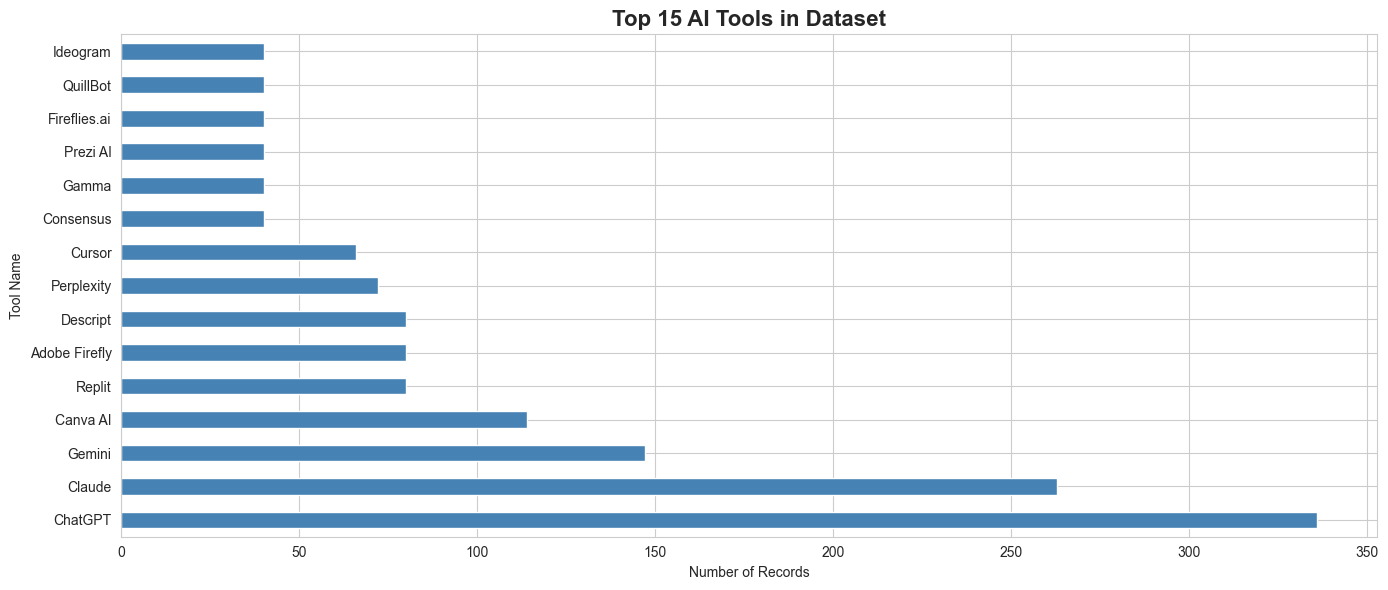

In [10]:
# Tool distribution
print("Top 15 AI Tools in Dataset:\n")
tool_counts = df['tool_name'].value_counts().head(15)
for tool, count in tool_counts.items():
    print(f"  {tool:30} : {count:3} occurrences")

# Visualization
plt.figure(figsize=(14, 6))
tool_counts.plot(kind='barh', color='steelblue')
plt.title('Top 15 AI Tools in Dataset', fontsize=16, fontweight='bold')
plt.xlabel('Number of Records')
plt.ylabel('Tool Name')
plt.tight_layout()
plt.show()


Task Categories:

  Writing & Marketing                 : 302 occurrences
  Research & Summarization            : 280 occurrences
  Image Generation                    : 261 occurrences
  Coding                              : 255 occurrences
  General Assistant                   : 250 occurrences
  No-Code App Building                : 240 occurrences
  Video Generation                    : 215 occurrences
  Meeting Transcription               : 200 occurrences
  Productivity & Notes                : 200 occurrences
  Translation                         : 191 occurrences
  Presentations                       : 183 occurrences
  Image Editing                       : 160 occurrences
  Music Generation                    : 160 occurrences
  Voice & Audio                       : 147 occurrences
  Data Analysis                       : 145 occurrences
  General Chat                        :  17 occurrences
  writing & marketing                 :  13 occurrences
  general assistant          

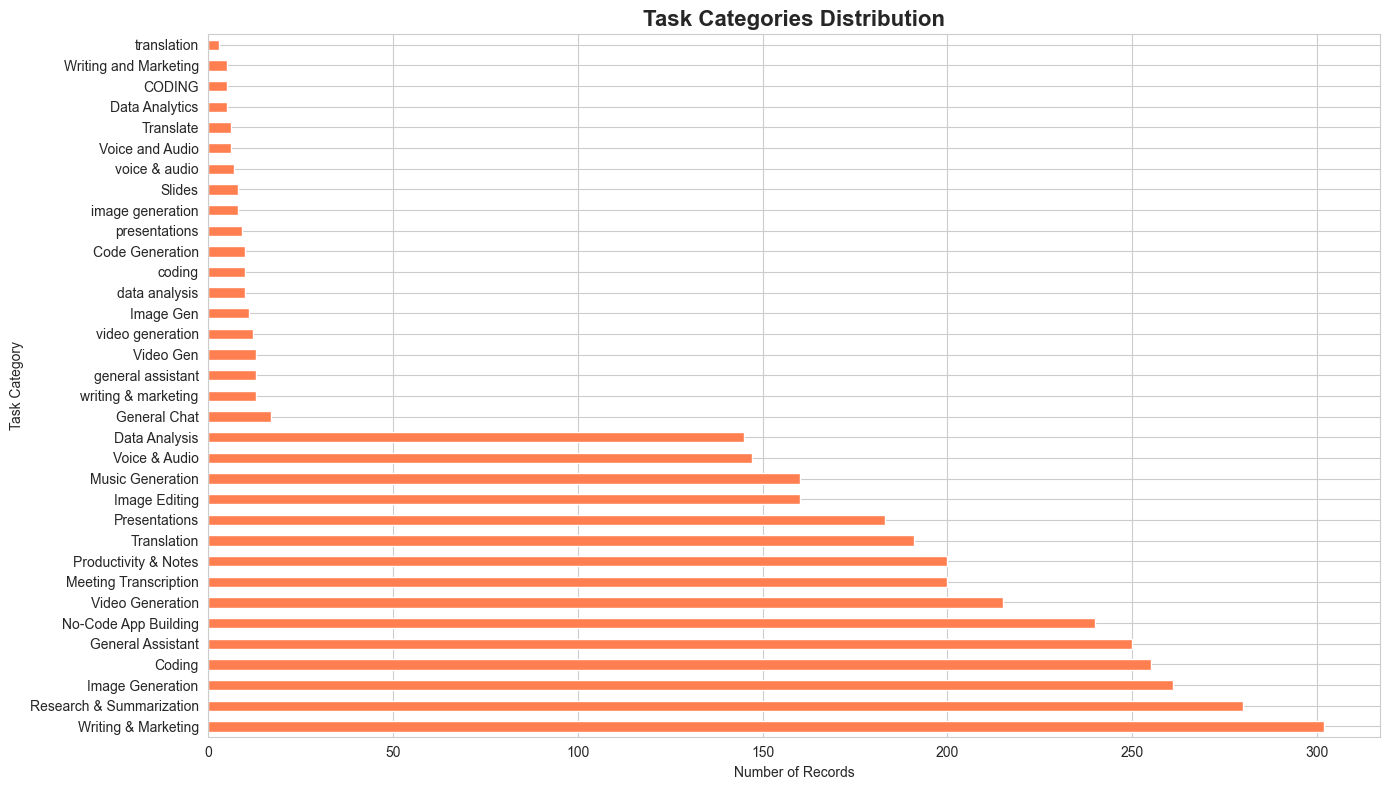

In [11]:
# Task category distribution
print("\nTask Categories:\n")
task_counts = df['task_category'].value_counts()
for task, count in task_counts.items():
    print(f"  {task:35} : {count:3} occurrences")

# Visualization
plt.figure(figsize=(14, 8))
task_counts.plot(kind='barh', color='coral')
plt.title('Task Categories Distribution', fontsize=16, fontweight='bold')
plt.xlabel('Number of Records')
plt.ylabel('Task Category')
plt.tight_layout()
plt.show()


Expertise Levels:

  Beginner        : 1738 (51.7%)
  Intermediate    : 762 (22.7%)
  Advanced        : 702 (20.9%)
  BEGINNER        :  33 (1.0%)
  Beg.            :  32 (1.0%)
  beginner        :  25 (0.7%)
  INTERMEDIATE    :  15 (0.4%)
  intermediate    :  15 (0.4%)
  advanced        :  12 (0.4%)
  Int.            :  10 (0.3%)
  Adv.            :   8 (0.2%)
  ADVANCED        :   8 (0.2%)


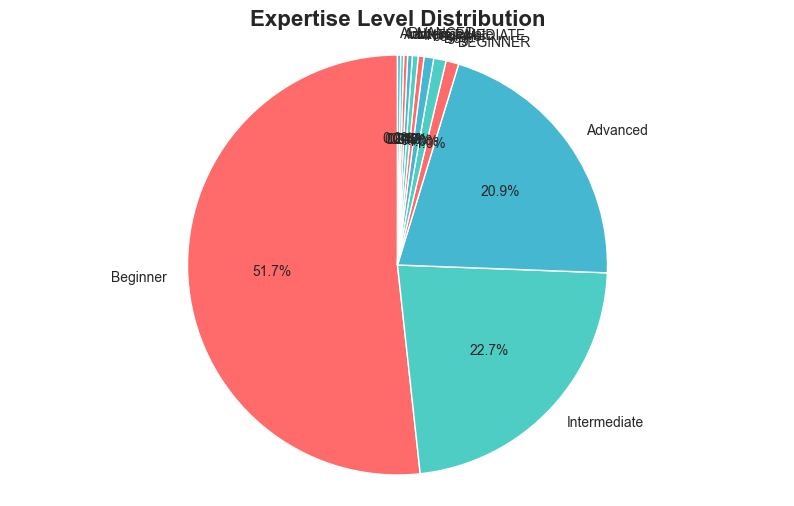

In [12]:
# Expertise level distribution
print("\nExpertise Levels:\n")
expertise_counts = df['expertise_level'].value_counts()
for level, count in expertise_counts.items():
    print(f"  {level:15} : {count:3} ({count/len(df)*100:.1f}%)")

# Visualization
plt.figure(figsize=(10, 6))
plt.pie(expertise_counts.values, labels=expertise_counts.index, autopct='%1.1f%%', startangle=90, colors=['#FF6B6B', '#4ECDC4', '#45B7D1'])
plt.title('Expertise Level Distribution', fontsize=16, fontweight='bold')
plt.axis('equal')
plt.show()

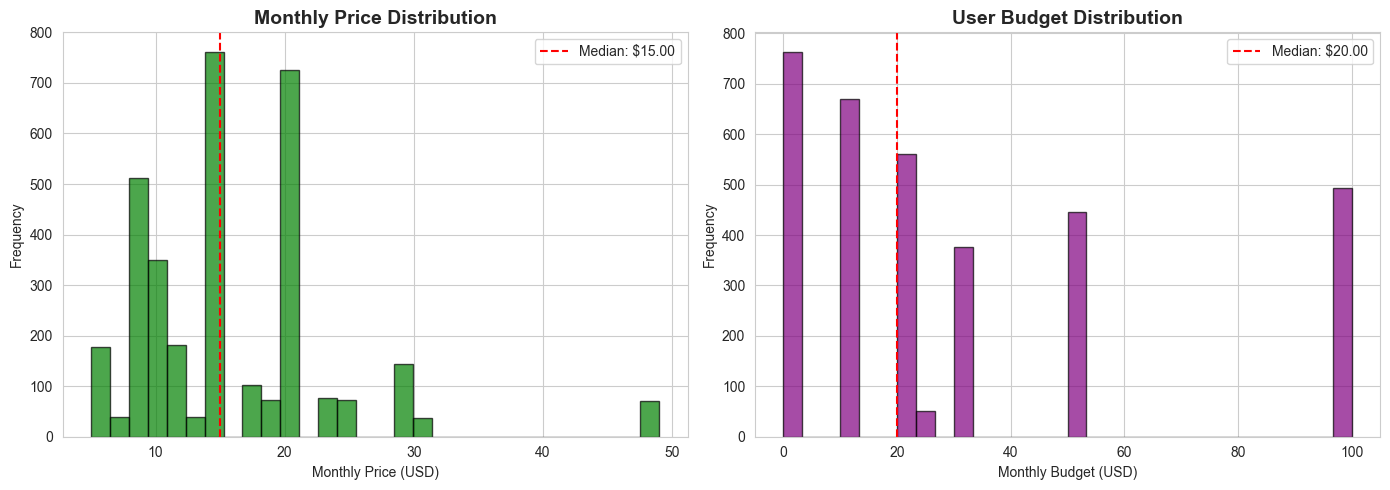

In [13]:
# Price distribution
plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
plt.hist(df['monthly_price_usd'].dropna(), bins=30, color='green', alpha=0.7, edgecolor='black')
plt.title('Monthly Price Distribution', fontsize=14, fontweight='bold')
plt.xlabel('Monthly Price (USD)')
plt.ylabel('Frequency')
plt.axvline(df['monthly_price_usd'].median(), color='red', linestyle='--', label=f"Median: ${df['monthly_price_usd'].median():.2f}")
plt.legend()

plt.subplot(1, 2, 2)
plt.hist(df['monthly_budget_usd'].dropna(), bins=30, color='purple', alpha=0.7, edgecolor='black')
plt.title('User Budget Distribution', fontsize=14, fontweight='bold')
plt.xlabel('Monthly Budget (USD)')
plt.ylabel('Frequency')
plt.axvline(df['monthly_budget_usd'].median(), color='red', linestyle='--', label=f"Median: ${df['monthly_budget_usd'].median():.2f}")
plt.legend()

plt.tight_layout()
plt.show()

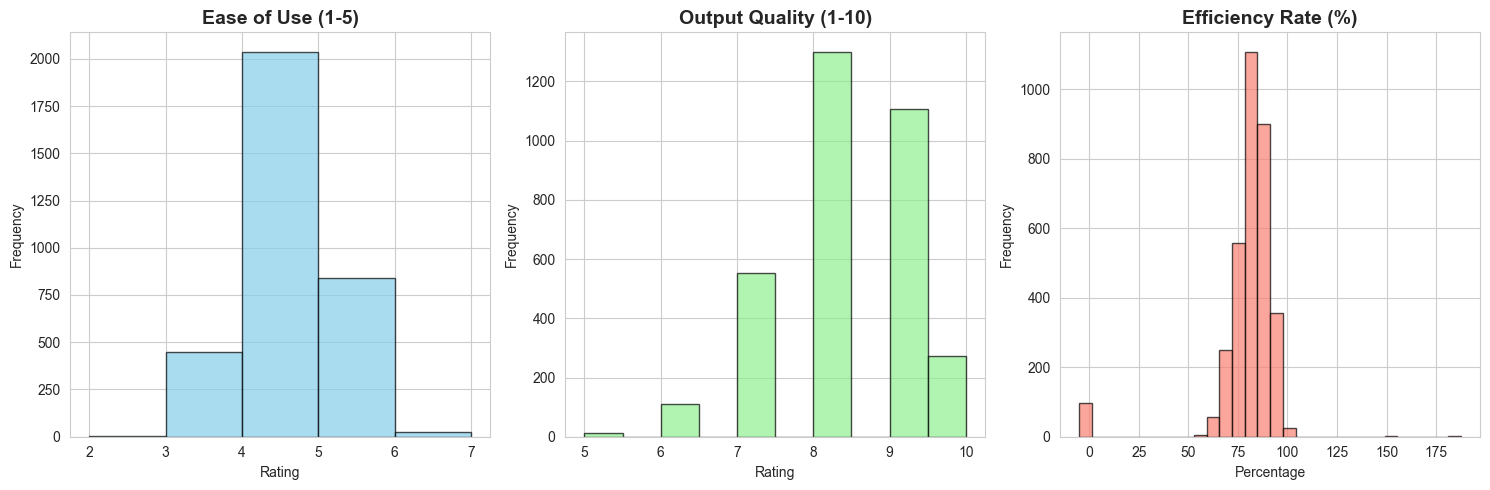

In [14]:
# Quality metrics distribution
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.hist(df['ease_of_use_1_5'].dropna(), bins=5, color='skyblue', alpha=0.7, edgecolor='black')
plt.title('Ease of Use (1-5)', fontsize=14, fontweight='bold')
plt.xlabel('Rating')
plt.ylabel('Frequency')

plt.subplot(1, 3, 2)
plt.hist(df['output_quality_1_10'].dropna(), bins=10, color='lightgreen', alpha=0.7, edgecolor='black')
plt.title('Output Quality (1-10)', fontsize=14, fontweight='bold')
plt.xlabel('Rating')
plt.ylabel('Frequency')

plt.subplot(1, 3, 3)
plt.hist(df['efficiency_rate_pct'].dropna(), bins=30, color='salmon', alpha=0.7, edgecolor='black')
plt.title('Efficiency Rate (%)', fontsize=14, fontweight='bold')
plt.xlabel('Percentage')
plt.ylabel('Frequency')

plt.tight_layout()
plt.show()

## 5. Feature Engineering

In [15]:
print("="*80)
print("FEATURE ENGINEERING")
print("="*80)

# Encode categorical variables
label_encoders = {}
categorical_features = []

# Add available categorical features
if 'expertise_level' in df.columns:
    categorical_features.append('expertise_level')
if 'task_category' in df.columns:
    categorical_features.append('task_category')
if 'platform' in df.columns:
    categorical_features.append('platform')
if 'best_model' in df.columns:
    categorical_features.append('best_model')

print(f"\nEncoding {len(categorical_features)} categorical features...")
for feature in categorical_features:
    le = LabelEncoder()
    df[feature + '_Encoded'] = le.fit_transform(df[feature])
    label_encoders[feature] = le
    print(f"  ✓ {feature}: {len(le.classes_)} unique classes")

# Numerical features
numerical_features = []
if 'monthly_budget_usd' in df.columns:
    numerical_features.append('monthly_budget_usd')
if 'monthly_price_usd' in df.columns:
    numerical_features.append('monthly_price_usd')
if 'ease_of_use_1_5' in df.columns:
    numerical_features.append('ease_of_use_1_5')
if 'output_quality_1_10' in df.columns:
    numerical_features.append('output_quality_1_10')
if 'efficiency_rate_pct' in df.columns:
    numerical_features.append('efficiency_rate_pct')
if 'free_plan_available' in df.columns:
    numerical_features.append('free_plan_available')
if 'annual_billing_available' in df.columns:
    numerical_features.append('annual_billing_available')

print(f"\nUsing {len(numerical_features)} numerical features")

# Create feature matrix
feature_columns = [f + '_Encoded' for f in categorical_features] + numerical_features
X = df[feature_columns].values
y = LabelEncoder().fit_transform(df['tool_name'])
label_encoders['tool_name'] = LabelEncoder().fit(df['tool_name'])

print(f"\n✓ Feature Matrix: {X.shape}")
print(f"✓ Total Features: {len(feature_columns)}")
print(f"✓ Target Classes: {len(np.unique(y))} unique tools")

FEATURE ENGINEERING

Encoding 4 categorical features...
  ✓ expertise_level: 12 unique classes
  ✓ task_category: 34 unique classes
  ✓ platform: 38 unique classes
  ✓ best_model: 66 unique classes

Using 7 numerical features

✓ Feature Matrix: (3360, 11)
✓ Total Features: 11
✓ Target Classes: 93 unique tools


## 6. Train/Test Split and Feature Scaling

In [16]:
# Check class distribution
unique, counts = np.unique(y, return_counts=True)
min_samples = counts.min()

print(f"Class Distribution:")
print(f"  Total classes: {len(unique)}")
print(f"  Min samples per class: {min_samples}")
print(f"  Max samples per class: {counts.max()}")
print(f"  Mean samples per class: {counts.mean():.1f}")

# Split data
test_size = 0.2
if min_samples >= 2:
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=test_size, random_state=42, stratify=y
    )
    print(f"\n✓ Stratified split: {len(X_train)} train, {len(X_test)} test")
else:
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=test_size, random_state=42
    )
    print(f"\n✓ Random split: {len(X_train)} train, {len(X_test)} test")

# Feature scaling
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"✓ Features scaled using StandardScaler")

# Determine CV folds
cv_folds = max(2, min(5, min_samples))
print(f"✓ Using {cv_folds} CV folds for hyperparameter tuning")

Class Distribution:
  Total classes: 93
  Min samples per class: 1
  Max samples per class: 336
  Mean samples per class: 36.1

✓ Random split: 2688 train, 672 test
✓ Features scaled using StandardScaler
✓ Using 2 CV folds for hyperparameter tuning


## 7. Model Training with Hyperparameter Tuning

### We'll train 6 different models:
1. Random Forest (with GridSearchCV)
2. Logistic Regression (with GridSearchCV)
3. K-Nearest Neighbors (with GridSearchCV). Voting Classifier (Ensemble)

In [17]:
print("="*80)
print("MODEL TRAINING WITH HYPERPARAMETER TUNING")
print("="*80)
print("\nThis may take several minutes...\n")

results = []

MODEL TRAINING WITH HYPERPARAMETER TUNING

This may take several minutes...



In [18]:
# 1. Random Forest with GridSearch
print("[1/6] Training Random Forest with GridSearchCV...")

rf_params = {
    'n_estimators': [100, 200],
    'max_depth': [10, 20, None],
    'min_samples_split': [2, 5],
    'max_features': ['sqrt', 'log2']
}

rf_grid = GridSearchCV(
    RandomForestClassifier(random_state=42, n_jobs=-1),
    rf_params,
    cv=cv_folds,
    n_jobs=1,
    verbose=0,
    scoring='accuracy'
)

rf_grid.fit(X_train_scaled, y_train)
rf_best = rf_grid.best_estimator_
rf_pred = rf_best.predict(X_test_scaled)
rf_acc = accuracy_score(y_test, rf_pred)

results.append({
    'Model': 'Random Forest (Tuned)',
    'Accuracy': rf_acc,
    'Best_Params': str(rf_grid.best_params_)
})

print(f"  Best params: {rf_grid.best_params_}")
print(f"  ✓ Accuracy: {rf_acc:.4f} ({rf_acc*100:.2f}%)")

[1/6] Training Random Forest with GridSearchCV...
  Best params: {'max_depth': 20, 'max_features': 'sqrt', 'min_samples_split': 5, 'n_estimators': 100}
  ✓ Accuracy: 0.9688 (96.88%)


In [19]:
# 2. Gradient Boosting with GridSearch
print("\n[2/6] Training Gradient Boosting with GridSearchCV...")

gb_params = {
    'n_estimators': [100, 200],
    'learning_rate': [0.01, 0.1],
    'max_depth': [3, 5],
    'min_samples_split': [2, 5]
}

gb_grid = GridSearchCV(
    GradientBoostingClassifier(random_state=42),
    gb_params,
    cv=cv_folds,
    n_jobs=-1,
    verbose=0,
    scoring='accuracy'
)

gb_grid.fit(X_train_scaled, y_train)
gb_best = gb_grid.best_estimator_
gb_pred = gb_best.predict(X_test_scaled)
gb_acc = accuracy_score(y_test, gb_pred)

results.append({
    'Model': 'Gradient Boosting (Tuned)',
    'Accuracy': gb_acc,
    'Best_Params': str(gb_grid.best_params_)
})

print(f"  Best params: {gb_grid.best_params_}")
print(f"  ✓ Accuracy: {gb_acc:.4f} ({gb_acc*100:.2f}%)")


[2/6] Training Gradient Boosting with GridSearchCV...
  Best params: {'learning_rate': 0.01, 'max_depth': 3, 'min_samples_split': 2, 'n_estimators': 200}
  ✓ Accuracy: 0.9524 (95.24%)


In [20]:
# 3. Logistic Regression
print("\n[3/6] Training Logistic Regression with GridSearchCV...")

lr_params = {
    'C': [0.1, 1, 10],
    'max_iter': [500, 1000],
    'solver': ['lbfgs', 'saga']
}

lr_grid = GridSearchCV(
    LogisticRegression(random_state=42),
    lr_params,
    cv=cv_folds,
    n_jobs=-1,
    verbose=0,
    scoring='accuracy'
)

lr_grid.fit(X_train_scaled, y_train)
lr_best = lr_grid.best_estimator_
lr_pred = lr_best.predict(X_test_scaled)
lr_acc = accuracy_score(y_test, lr_pred)

results.append({
    'Model': 'Logistic Regression (Tuned)',
    'Accuracy': lr_acc,
    'Best_Params': str(lr_grid.best_params_)
})

print(f"  Best params: {lr_grid.best_params_}")
print(f"  ✓ Accuracy: {lr_acc:.4f} ({lr_acc*100:.2f}%)")


[3/6] Training Logistic Regression with GridSearchCV...
  Best params: {'C': 10, 'max_iter': 500, 'solver': 'lbfgs'}
  ✓ Accuracy: 0.8482 (84.82%)


In [21]:
# 4. K-Nearest Neighbors
print("\n[4/6] Training K-Nearest Neighbors with GridSearchCV...")

knn_params = {
    'n_neighbors': [3, 5, 7],
    'weights': ['uniform', 'distance'],
    'metric': ['euclidean', 'manhattan']
}

knn_grid = GridSearchCV(
    KNeighborsClassifier(),
    knn_params,
    cv=cv_folds,
    n_jobs=-1,
    verbose=0,
    scoring='accuracy'
)

knn_grid.fit(X_train_scaled, y_train)
knn_best = knn_grid.best_estimator_
knn_pred = knn_best.predict(X_test_scaled)
knn_acc = accuracy_score(y_test, knn_pred)

results.append({
    'Model': 'KNN (Tuned)',
    'Accuracy': knn_acc,
    'Best_Params': str(knn_grid.best_params_)
})

print(f"  Best params: {knn_grid.best_params_}")
print(f"  ✓ Accuracy: {knn_acc:.4f} ({knn_acc*100:.2f}%)")


[4/6] Training K-Nearest Neighbors with GridSearchCV...
  Best params: {'metric': 'manhattan', 'n_neighbors': 7, 'weights': 'distance'}
  ✓ Accuracy: 0.8661 (86.61%)


In [22]:
# 5. Voting Classifier (Ensemble)
print("\n[5/6] Training Voting Classifier (Ensemble)...")

voting_clf = VotingClassifier(
    estimators=[
        ('rf', rf_best),
        ('gb', gb_best),
        ('lr', lr_best)
    ],
    voting='hard',
    n_jobs=-1
)

voting_clf.fit(X_train_scaled, y_train)
voting_pred = voting_clf.predict(X_test_scaled)
voting_acc = accuracy_score(y_test, voting_pred)

results.append({
    'Model': 'Voting Ensemble',
    'Accuracy': voting_acc,
    'Best_Params': 'RF + GB + LR'
})

print(f"  ✓ Accuracy: {voting_acc:.4f} ({voting_acc*100:.2f}%)")


[5/6] Training Voting Classifier (Ensemble)...
  ✓ Accuracy: 0.9613 (96.13%)


In [23]:
# 6. Stacking Classifier (Advanced Ensemble)
print("\n[6/6] Training Stacking Classifier (Advanced Ensemble)...")

stacking_clf = StackingClassifier(
    estimators=[
        ('rf', rf_best),
        ('gb', gb_best),
        ('knn', knn_best)
    ],
    final_estimator=LogisticRegression(max_iter=1000, random_state=42),
    cv=cv_folds,
    n_jobs=-1
)

stacking_clf.fit(X_train_scaled, y_train)
stacking_pred = stacking_clf.predict(X_test_scaled)
stacking_acc = accuracy_score(y_test, stacking_pred)

results.append({
    'Model': 'Stacking Ensemble',
    'Accuracy': stacking_acc,
    'Best_Params': 'RF + GB + KNN → LR'
})

print(f"  ✓ Accuracy: {stacking_acc:.4f} ({stacking_acc*100:.2f}%)")
print("\n✓ All models trained successfully!")


[6/6] Training Stacking Classifier (Advanced Ensemble)...
  ✓ Accuracy: 0.9702 (97.02%)

✓ All models trained successfully!


## 8. Model Comparison and Selection

In [24]:
# Create results dataframe
results_df = pd.DataFrame(results)
results_df = results_df.sort_values('Accuracy', ascending=False)
results_df.to_csv('model_performance_results.csv', index=False)

print("="*80)
print("MODEL PERFORMANCE COMPARISON")
print("="*80)
print()
for idx, row in results_df.iterrows():
    print(f"{row['Model']:35} | Accuracy: {row['Accuracy']:.4f} ({row['Accuracy']*100:.2f}%)")

best_model_name = results_df.iloc[0]['Model']
best_accuracy = results_df.iloc[0]['Accuracy']

print()
print("="*80)
print(f"🏆 BEST MODEL: {best_model_name}")
print(f"🎯 ACCURACY: {best_accuracy:.4f} ({best_accuracy*100:.2f}%)")
print("="*80)

MODEL PERFORMANCE COMPARISON

Stacking Ensemble                   | Accuracy: 0.9702 (97.02%)
Random Forest (Tuned)               | Accuracy: 0.9688 (96.88%)
Voting Ensemble                     | Accuracy: 0.9613 (96.13%)
Gradient Boosting (Tuned)           | Accuracy: 0.9524 (95.24%)
KNN (Tuned)                         | Accuracy: 0.8661 (86.61%)
Logistic Regression (Tuned)         | Accuracy: 0.8482 (84.82%)

🏆 BEST MODEL: Stacking Ensemble
🎯 ACCURACY: 0.9702 (97.02%)


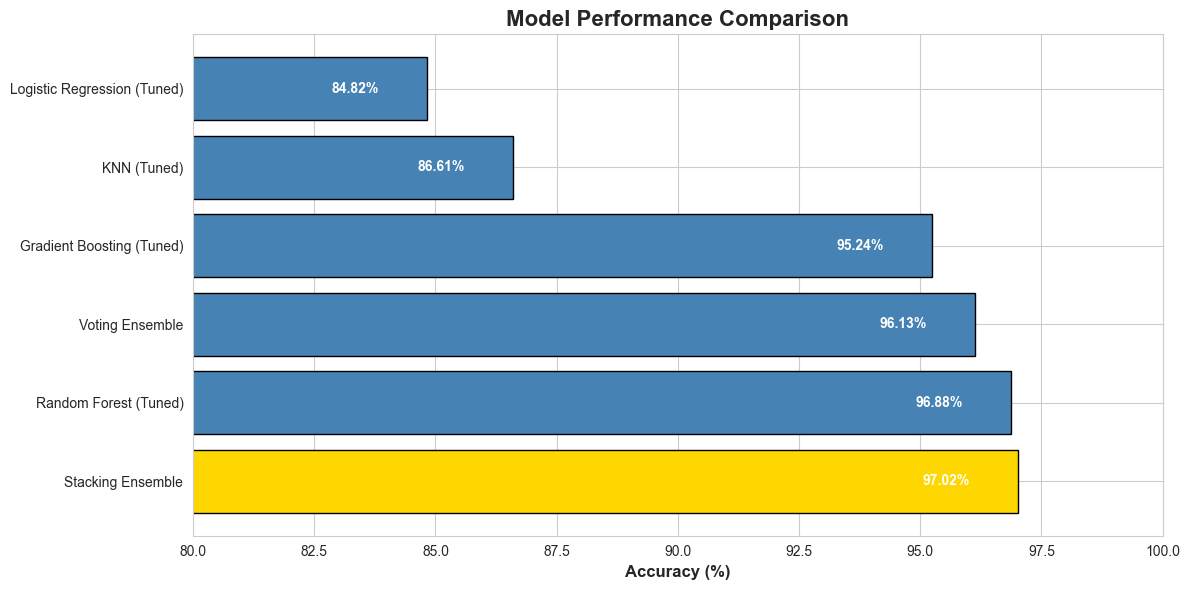

In [25]:
# Visualize model comparison
plt.figure(figsize=(12, 6))
colors = ['gold' if i == 0 else 'steelblue' for i in range(len(results_df))]
plt.barh(results_df['Model'], results_df['Accuracy']*100, color=colors, edgecolor='black')
plt.xlabel('Accuracy (%)', fontsize=12, fontweight='bold')
plt.title('Model Performance Comparison', fontsize=16, fontweight='bold')
plt.xlim(80, 100)
for i, (idx, row) in enumerate(results_df.iterrows()):
    plt.text(row['Accuracy']*100 - 1, i, f"{row['Accuracy']*100:.2f}%", 
             va='center', ha='right', fontweight='bold', color='white')
plt.tight_layout()
plt.show()

## 9. Save Best Model

In [26]:
# Select best model for saving
model_mapping = {
    'Random Forest (Tuned)': rf_best,
    'Gradient Boosting (Tuned)': gb_best,
    'Logistic Regression (Tuned)': lr_best,
    'KNN (Tuned)': knn_best,
    'Voting Ensemble': voting_clf,
    'Stacking Ensemble': stacking_clf
}

best_model = model_mapping[best_model_name]

# Save model artifacts
print("\nSaving model artifacts...")
joblib.dump(best_model, 'best_model.pkl')
print("  ✓ Saved: best_model.pkl")

joblib.dump(scaler, 'scaler.pkl')
print("  ✓ Saved: scaler.pkl")

joblib.dump(label_encoders, 'label_encoders.pkl')
print("  ✓ Saved: label_encoders.pkl")

print("\n✓ All artifacts saved successfully!")


Saving model artifacts...
  ✓ Saved: best_model.pkl
  ✓ Saved: scaler.pkl
  ✓ Saved: label_encoders.pkl

✓ All artifacts saved successfully!


## 10. Detailed Model Evaluation

In [27]:
# Top 10 most common tools in test set
print("Top 10 Most Common Tools in Test Set:\n")
y_test_tools = label_encoders['tool_name'].inverse_transform(y_test)
test_tool_counts = pd.Series(y_test_tools).value_counts().head(10)

for tool, count in test_tool_counts.items():
    print(f"  {tool:40} : {count} occurrences")

Top 10 Most Common Tools in Test Set:

  ChatGPT                                  : 79 occurrences
  Claude                                   : 54 occurrences
  Gemini                                   : 30 occurrences
  Canva AI                                 : 25 occurrences
  Adobe Firefly                            : 21 occurrences
  Descript                                 : 20 occurrences
  Cursor                                   : 18 occurrences
  Perplexity                               : 15 occurrences
  Replit                                   : 15 occurrences
  Fathom                                   : 13 occurrences


In [28]:
# Classification report for top 10 tools
print("\nClassification Report (Top 10 Tools):\n")
best_pred = best_model.predict(X_test_scaled)
pred_tools = label_encoders['tool_name'].inverse_transform(best_pred)

top_10_tools = test_tool_counts.index.tolist()
mask = pd.Series(y_test_tools).isin(top_10_tools).values

if mask.sum() > 0:
    filtered_y_test = [y for y, m in zip(y_test_tools, mask) if m]
    filtered_y_pred = [p for p, m in zip(pred_tools, mask) if m]
    print(classification_report(filtered_y_test, filtered_y_pred, 
                              labels=top_10_tools,
                              zero_division=0))


Classification Report (Top 10 Tools):

               precision    recall  f1-score   support

      ChatGPT       1.00      1.00      1.00        79
       Claude       0.98      1.00      0.99        54
       Gemini       1.00      1.00      1.00        30
     Canva AI       1.00      1.00      1.00        25
Adobe Firefly       1.00      1.00      1.00        21
     Descript       1.00      1.00      1.00        20
       Cursor       1.00      1.00      1.00        18
   Perplexity       1.00      1.00      1.00        15
       Replit       1.00      0.93      0.97        15
       Fathom       1.00      1.00      1.00        13

     accuracy                           1.00       290
    macro avg       1.00      0.99      1.00       290
 weighted avg       1.00      1.00      1.00       290



In [31]:
# Feature importance (if available)
if hasattr(best_model, 'feature_importances_'):
    print("\nTop 10 Most Important Features:\n")
    feature_names = [f.replace('_Encoded', '') for f in feature_columns]
    importances = best_model.feature_importances_
    indices = np.argsort(importances)[::-1][:10]
    
    for i, idx in enumerate(indices, 1):
        print(f"{i:2}. {feature_names[idx]:30} | Importance: {importances[idx]:.4f}")
    
    # Visualize feature importance
    plt.figure(figsize=(12, 6))
    top_features = [feature_names[i] for i in indices]
    top_importances = [importances[i] for i in indices]
    plt.barh(top_features, top_importances, color='teal', edgecolor='black')
    plt.xlabel('Feature Importance', fontsize=12, fontweight='bold')
    plt.title('Top 10 Most Important Features', fontsize=16, fontweight='bold')
    plt.tight_layout()
    plt.show()

## 11. Final Summary

In [30]:
print("="*80)
print("✅ TRAINING COMPLETE!")
print("="*80)
print(f"\nDataset: {cleaned_count:,} records")
print(f"Features: {len(feature_columns)}")
print(f"Tool Classes: {len(np.unique(y))}")
print(f"Best Model: {best_model_name}")
print(f"Test Accuracy: {best_accuracy*100:.2f}%")
print(f"\nFiles generated:")
print(f"  - cleaned_toolmatcher_dataset.csv")
print(f"  - model_performance_results.csv")
print(f"  - best_model.pkl")
print(f"  - scaler.pkl")
print(f"  - label_encoders.pkl")
print("="*80)

✅ TRAINING COMPLETE!

Dataset: 3,360 records
Features: 11
Tool Classes: 93
Best Model: Stacking Ensemble
Test Accuracy: 97.02%

Files generated:
  - cleaned_toolmatcher_dataset.csv
  - model_performance_results.csv
  - best_model.pkl
  - scaler.pkl
  - label_encoders.pkl
